# Practice Session 07: Connected components and k-core decomposition

# 1. The Star Wars graph

In [1]:
import io
import networkx as nx
import matplotlib.pyplot as plt
import random
import numpy as np
import statistics

In [2]:
INPUT_GRAPH_FILENAME = "starwars.graphml"

In [3]:
# LEAVE AS-IS

# Read the graph in GraphML format
g_in = nx.read_graphml(INPUT_GRAPH_FILENAME)

# Re-label the nodes so they use the 'name' as label
g_relabeled = nx.relabel.relabel_nodes(g_in, dict(g_in.nodes(data='name')))

# Convert the graph to undirected
g = g_relabeled.to_undirected()

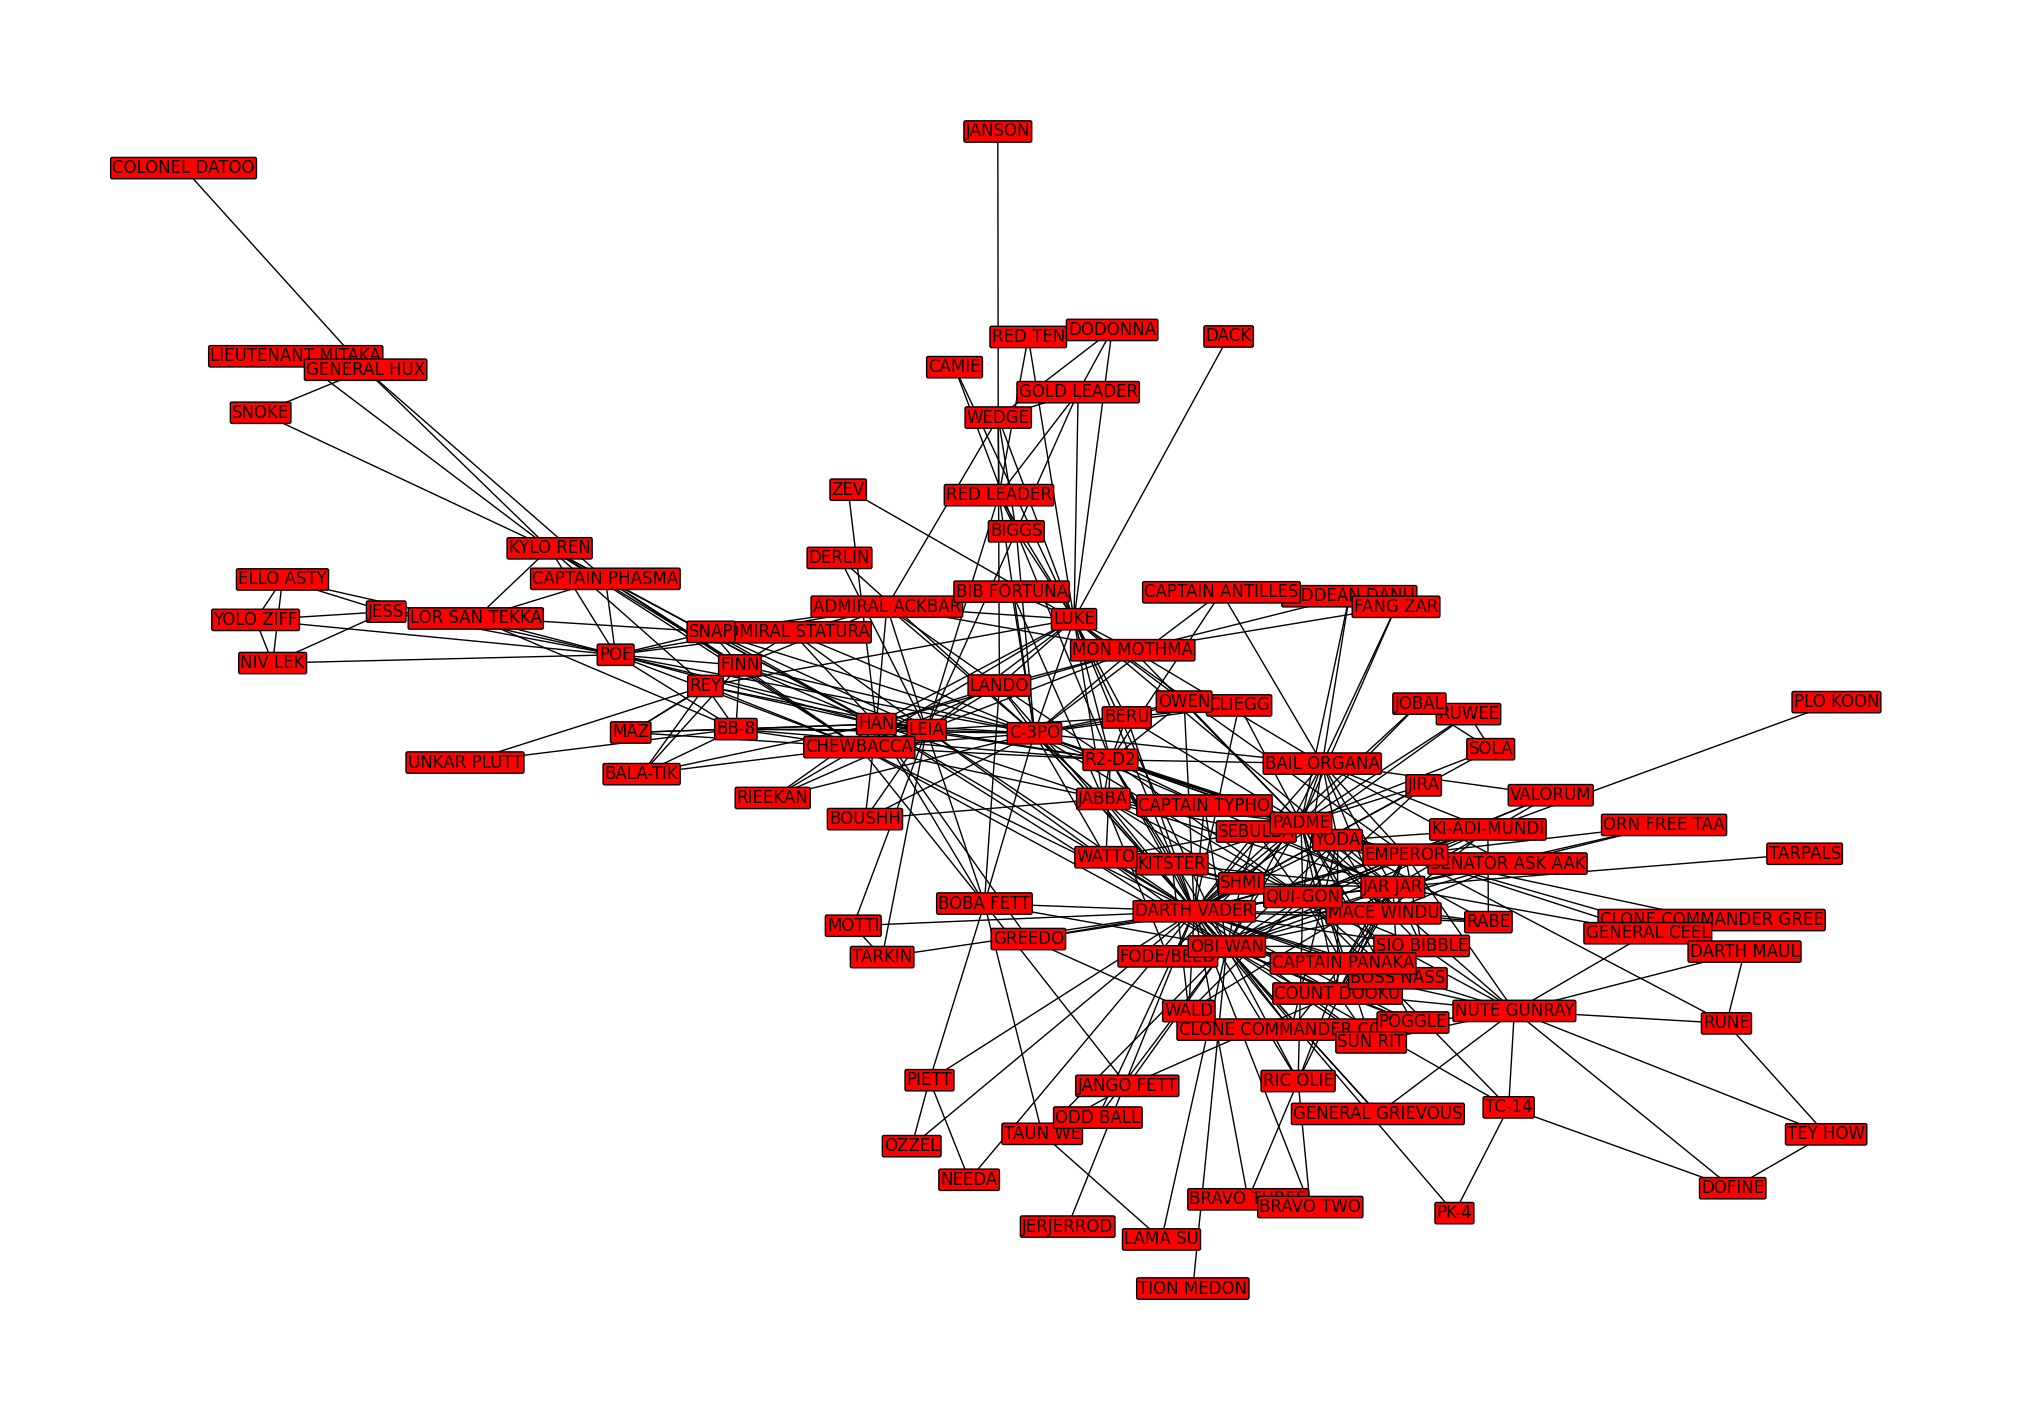

In [4]:
# LEAVE AS-IS (OR MODIFY IF YOU WANT)

def plot_graph(g):

    # Create a plot of 20x14
    plt.figure(figsize=(20,14))

    # Layout the nodes using a spring model
    nx.draw_spring(g, with_labels=True, node_size=1, bbox=dict(facecolor="red", edgecolor='black', boxstyle='round,pad=0.1'))

    # Display
    plt.show()

plot_graph(g)

It is a connected graph becouse it only has one connected component.

In [ ]:
degrees = [degree for node, degree in g.degree()]

average_degree = np.mean(degrees)
std_dev_degree = np.std(degrees)

print(f"Average degree: {average_degree:.1f}")
print(f"Standard deviation of degree: {std_dev_degree:.1f}")

Average degree: 8.1
Standard deviation of degree: 8.6


It is probably a scale-free network because as we can observe, when plotting the degree distribution in a log-log scale, there are a lot of nodes with fewer degrees in comparison with the number of large degree nodes (which are the hubs). The code below plots the degree distribution and can be observed what we just mentioned.

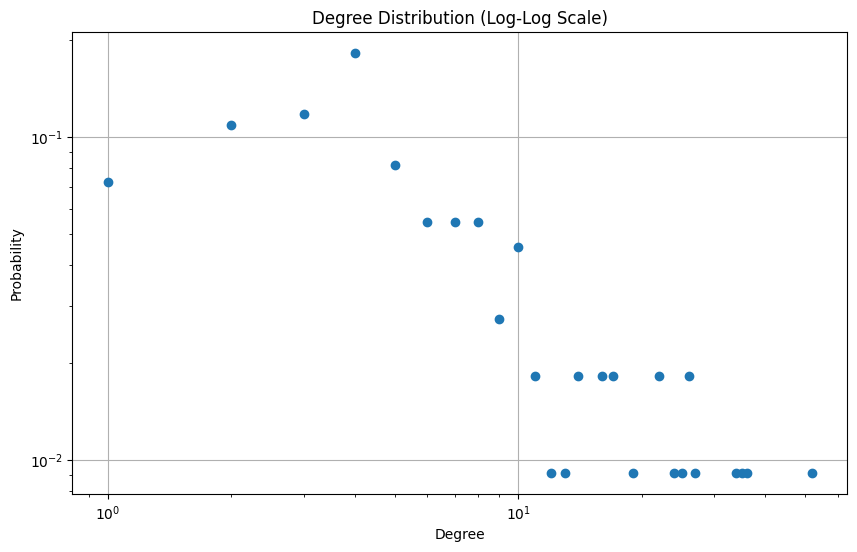

In [ ]:
# Compute the degree distribution
degree_counts = np.bincount(degrees)
degree_probabilities = degree_counts / len(degrees)

# Plot 
plt.figure(figsize=(10, 6))
plt.loglog(range(len(degree_probabilities)), degree_probabilities, marker='o', linestyle='None')
plt.title('Degree Distribution (Log-Log Scale)')
plt.xlabel('Degree')
plt.ylabel('Probability')
plt.grid(True)
plt.show()

# 2. Remove a fraction of edges

In [6]:
# LEAVE AS-IS

def remove_edges_uniformly_at_random(g_in, p):
    # Check input is within bounds
    if p < 0.0 or p > 1.0:
        raise ValueError

    # Create a copy of the input graph
    g_out = g_in.copy()

    # Decide how many edges should be in the output graph
    target_num_edges = int((1.0-p) * g_in.number_of_edges())

    # While there are more edges than desired
    while g_out.number_of_edges() > target_num_edges:

        # Remove one random edge
        edge = random.choice(list(g_out.edges()))

        if g_out.has_edge(edge[0], edge[1]):
            g_out.remove_edge(edge[0], edge[1])

    # Return the resulting graph
    return g_out

<font size="+1" color="red">Replace this cell with code to create g15, g50, g85 as described above, and to plot these three graphs. Use three different cells for the plots. *Tip: g85, should be keeping 85% of the edges.* </font>

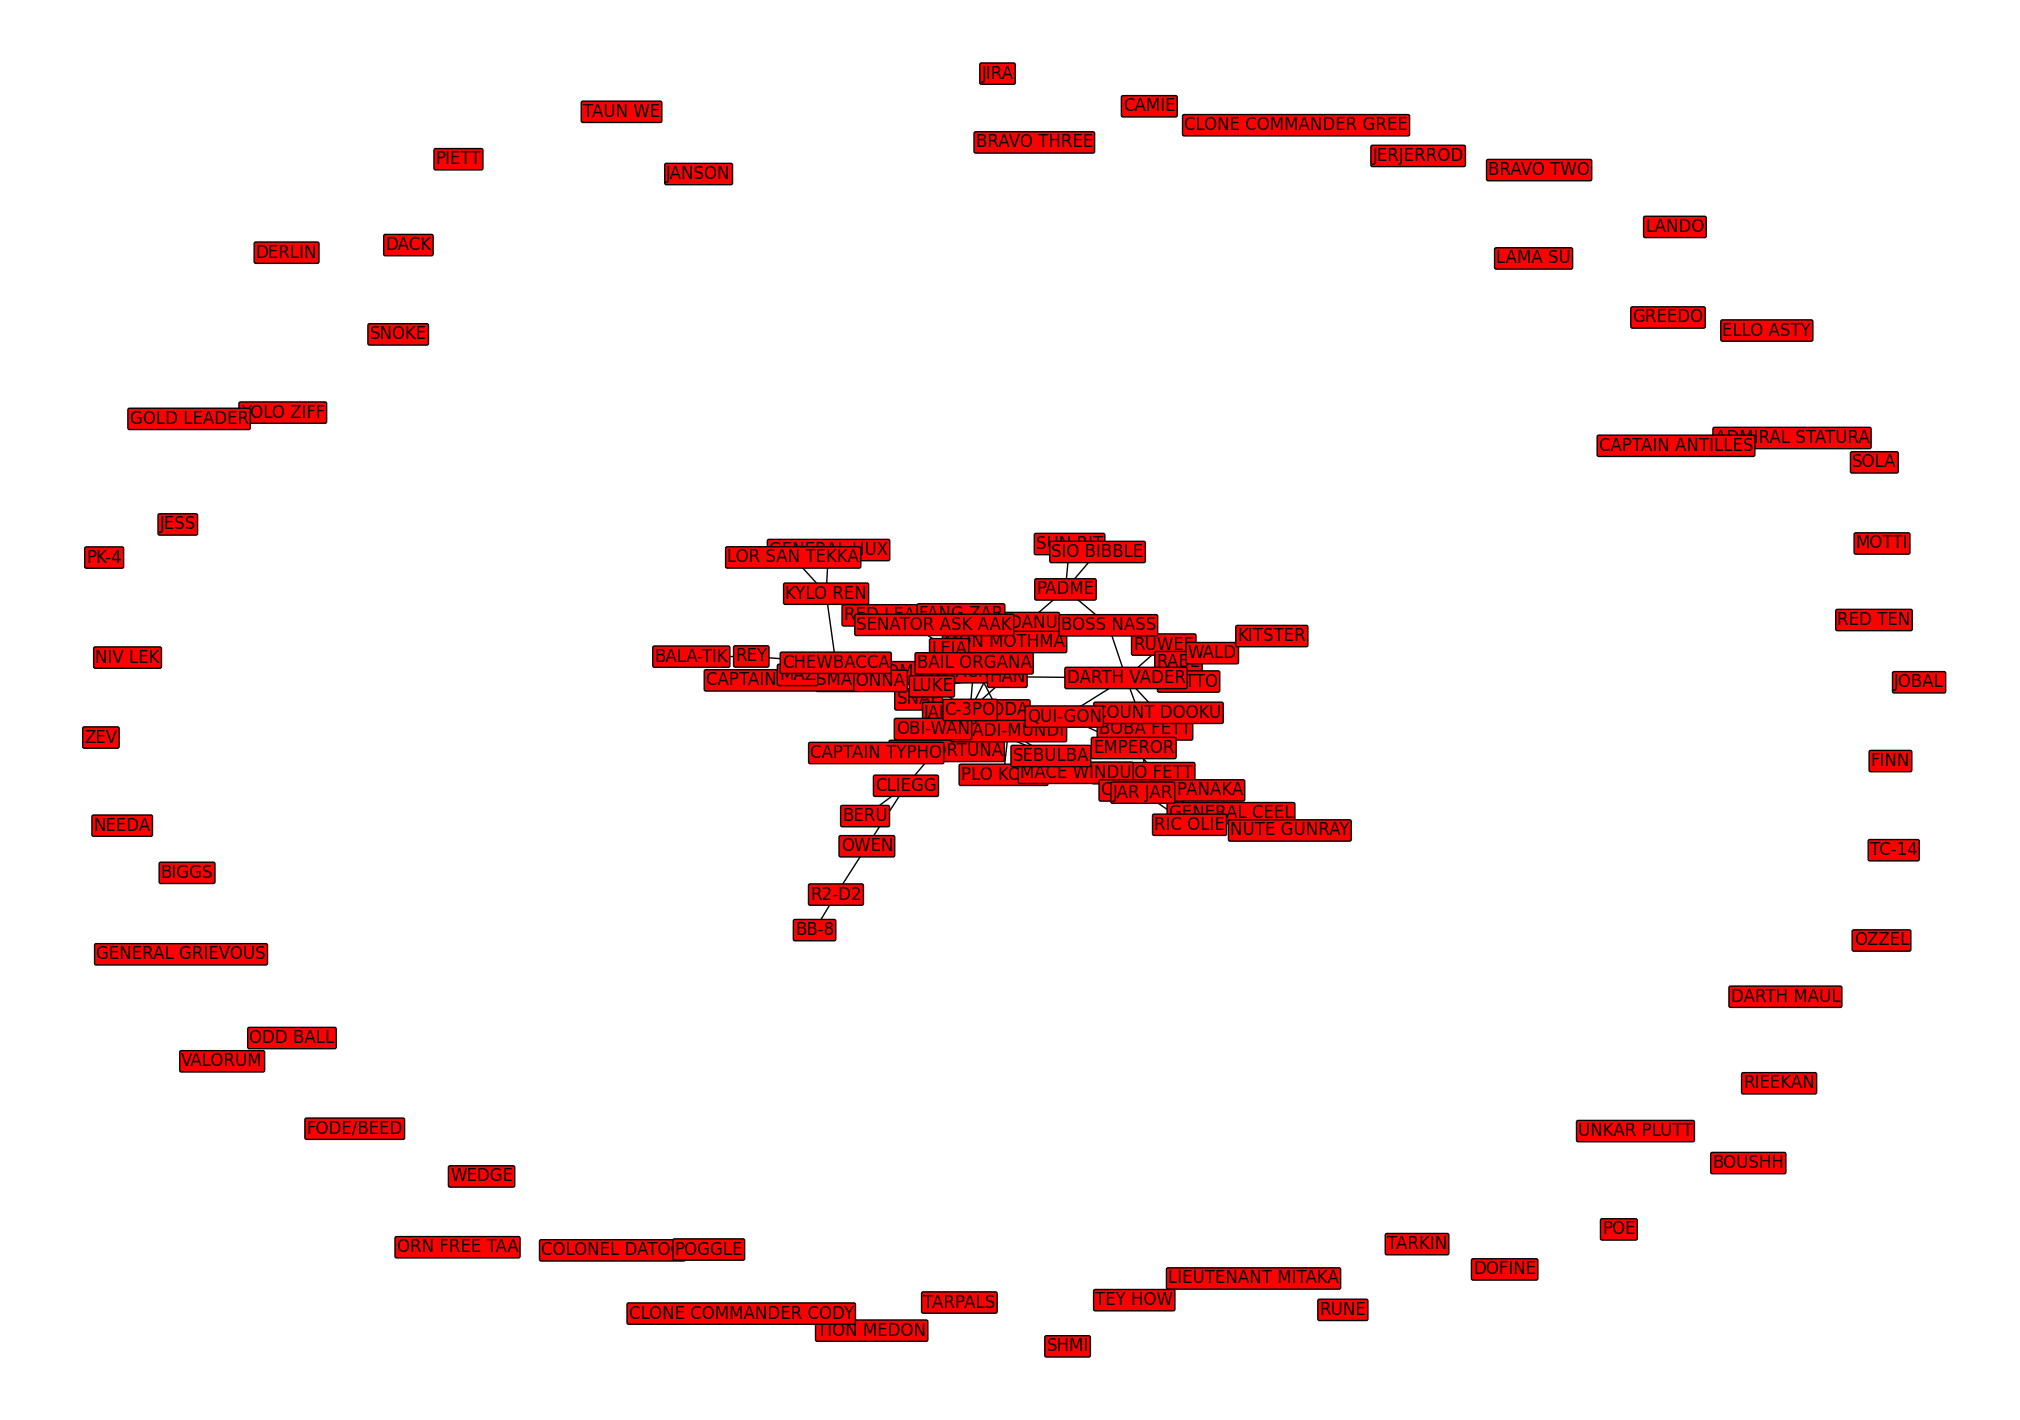

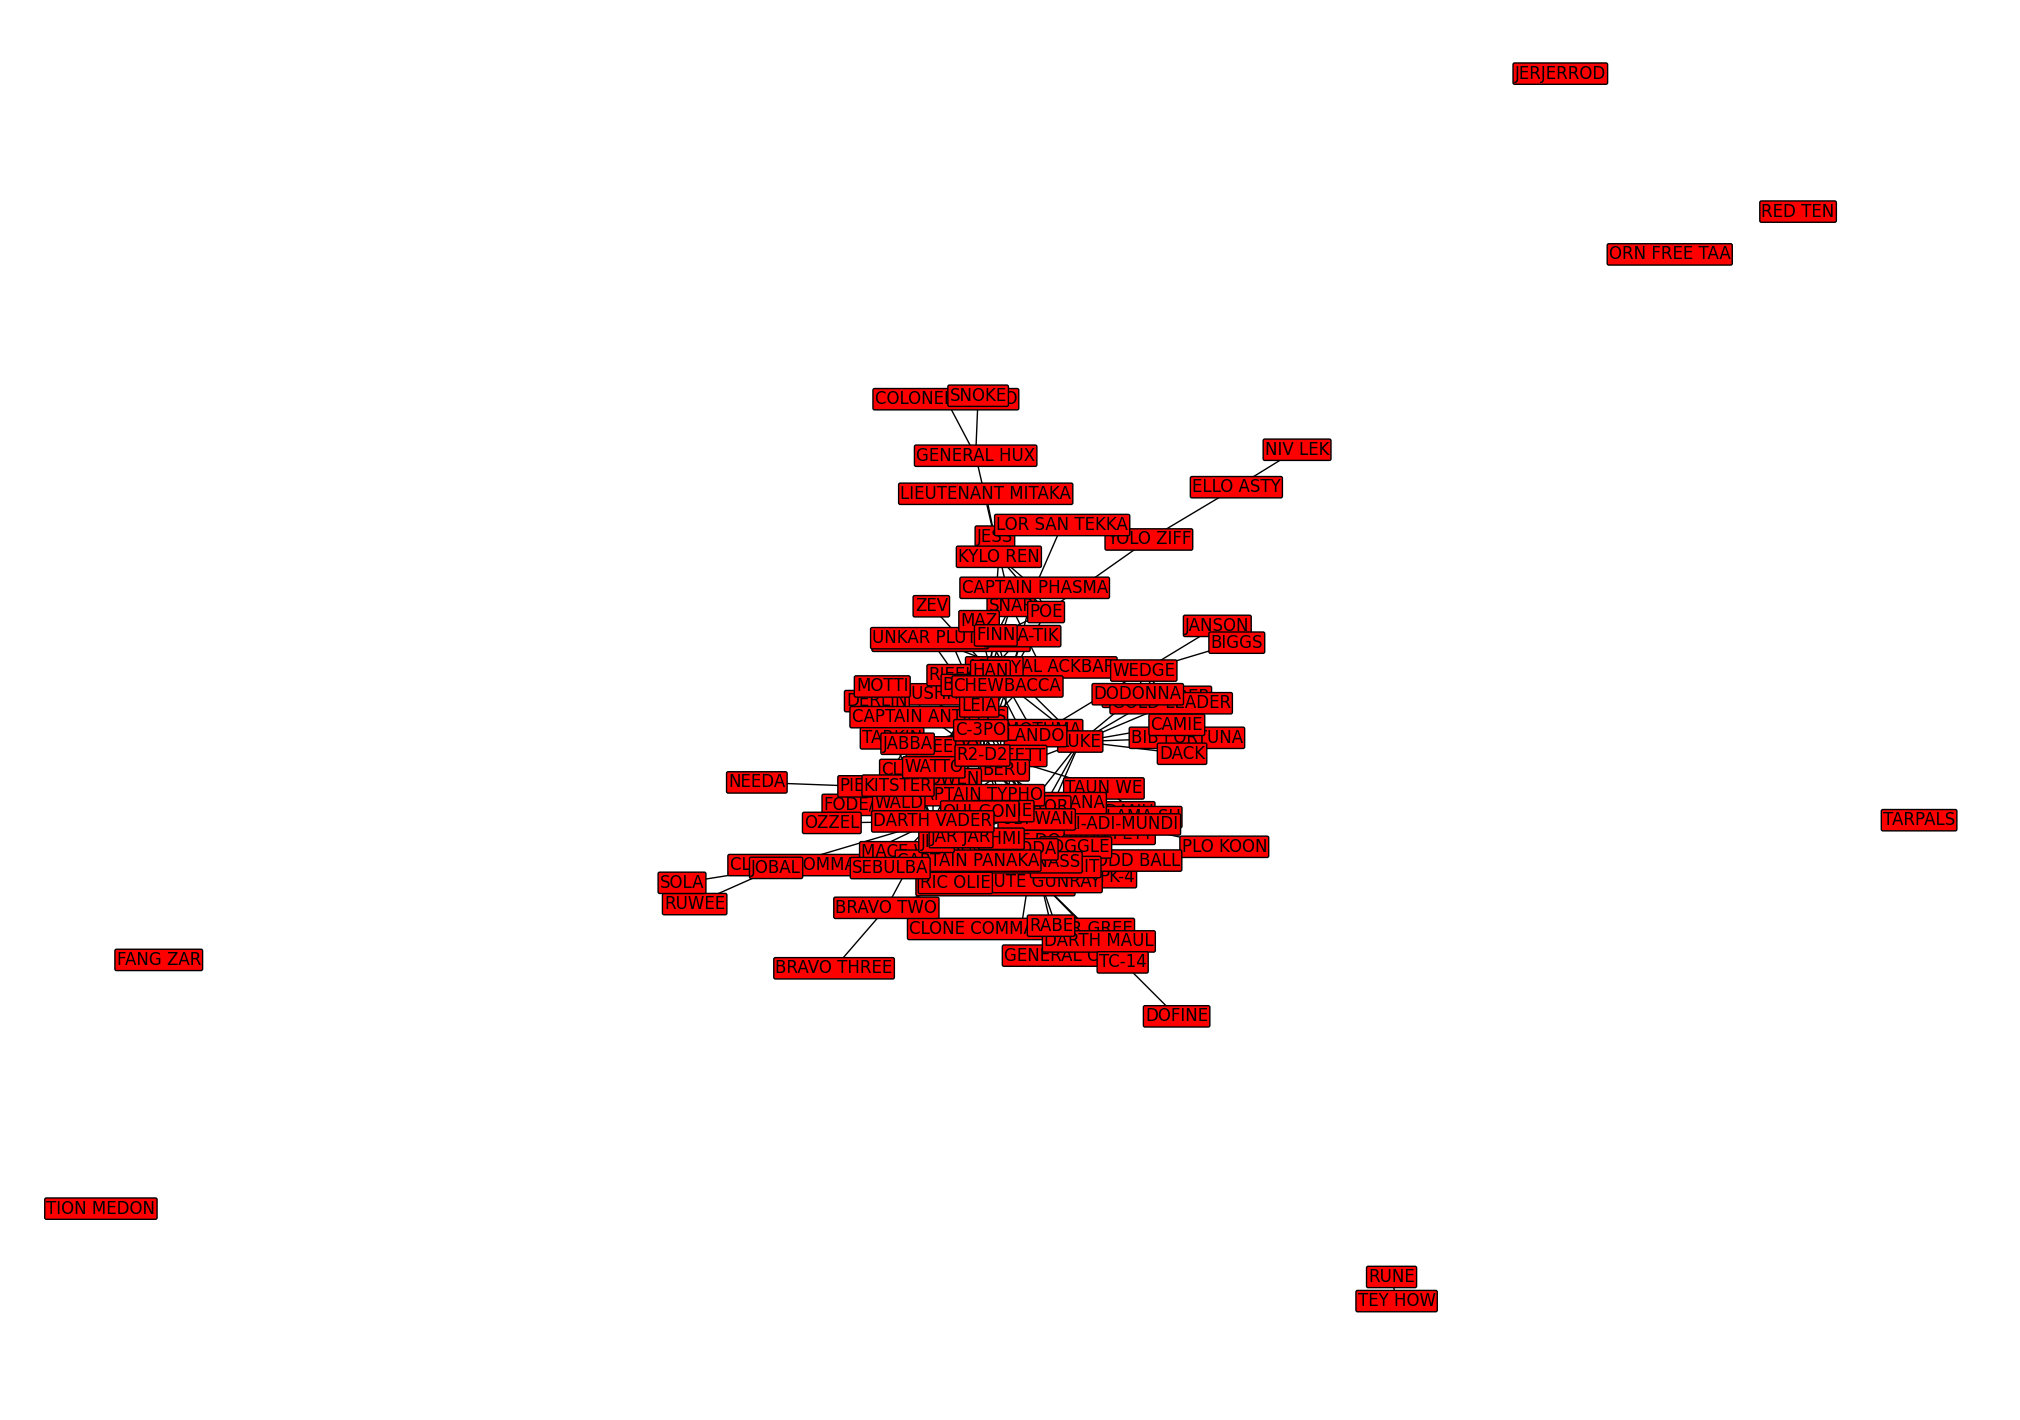

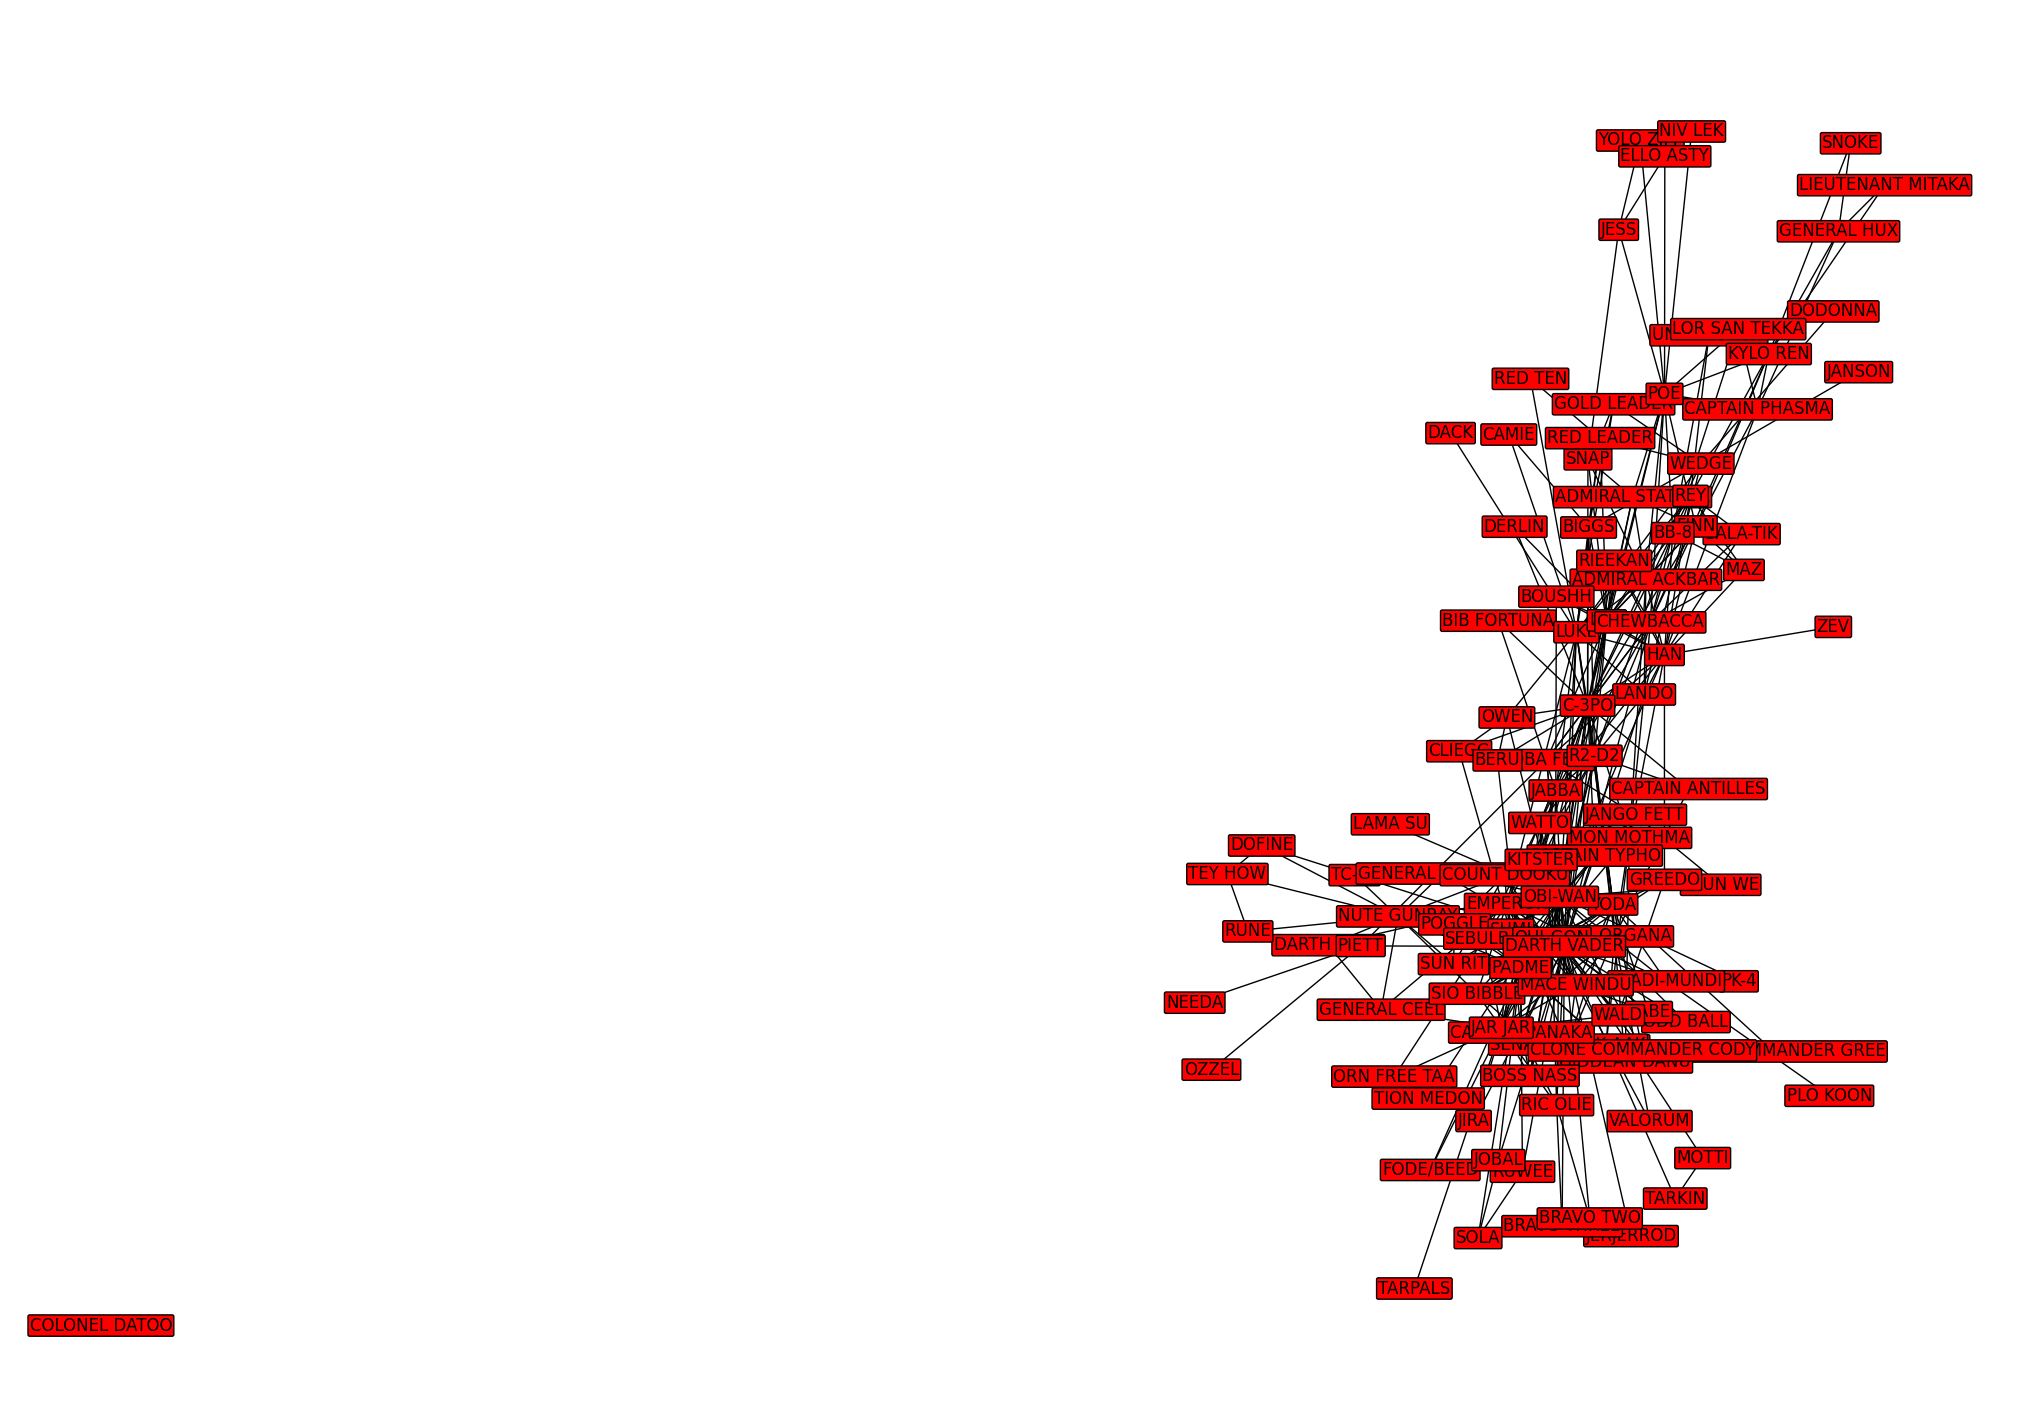

In [ ]:
g15 = remove_edges_uniformly_at_random(g, 0.85)
g50 = remove_edges_uniformly_at_random(g, 0.50)
g85 = remove_edges_uniformly_at_random(g, 0.15)

plot_graph(g15)
plot_graph(g50)
plot_graph(g85)

In the graphs above, we can observe a progression of the relation between the number of singletons and the size of the largest connected component. In the first case, there is a high number of singletons and a small large connected component. In the second case, there is a fewer number of singletons and a larger connected component. Finally, in the last graph, there is a big single connected component and only one singleton on the left.

In [9]:
# LEAVE AS-IS

def remove_edges_by_betweenness(g_in, p):
    # Check input is within bounds
    if p < 0.0 or p > 1.0:
        raise ValueError

    # Create a copy of the input graph
    g_out = g_in.copy()

    # Compute edge betweenness
    #edge_betweenness = nx.algorithms.centrality.edge_betweenness(g_out)
    edge_betweenness = nx.edge_betweenness_centrality(g_out)
    edges_by_betweenness = sorted(edge_betweenness.items(), key=lambda x:x[1], reverse=True)

    # Decide how many edges should be in the output graph
    target_num_edges = int((1.0-p) * g_in.number_of_edges())

    # While there are more edges than desired
    while g_out.number_of_edges() > target_num_edges:

        to_remove = edges_by_betweenness.pop(0)
        edge_to_remove = to_remove[0]

        g_out.remove_edge(edge_to_remove[0], edge_to_remove[1])

    # Return the resulting graph
    return g_out

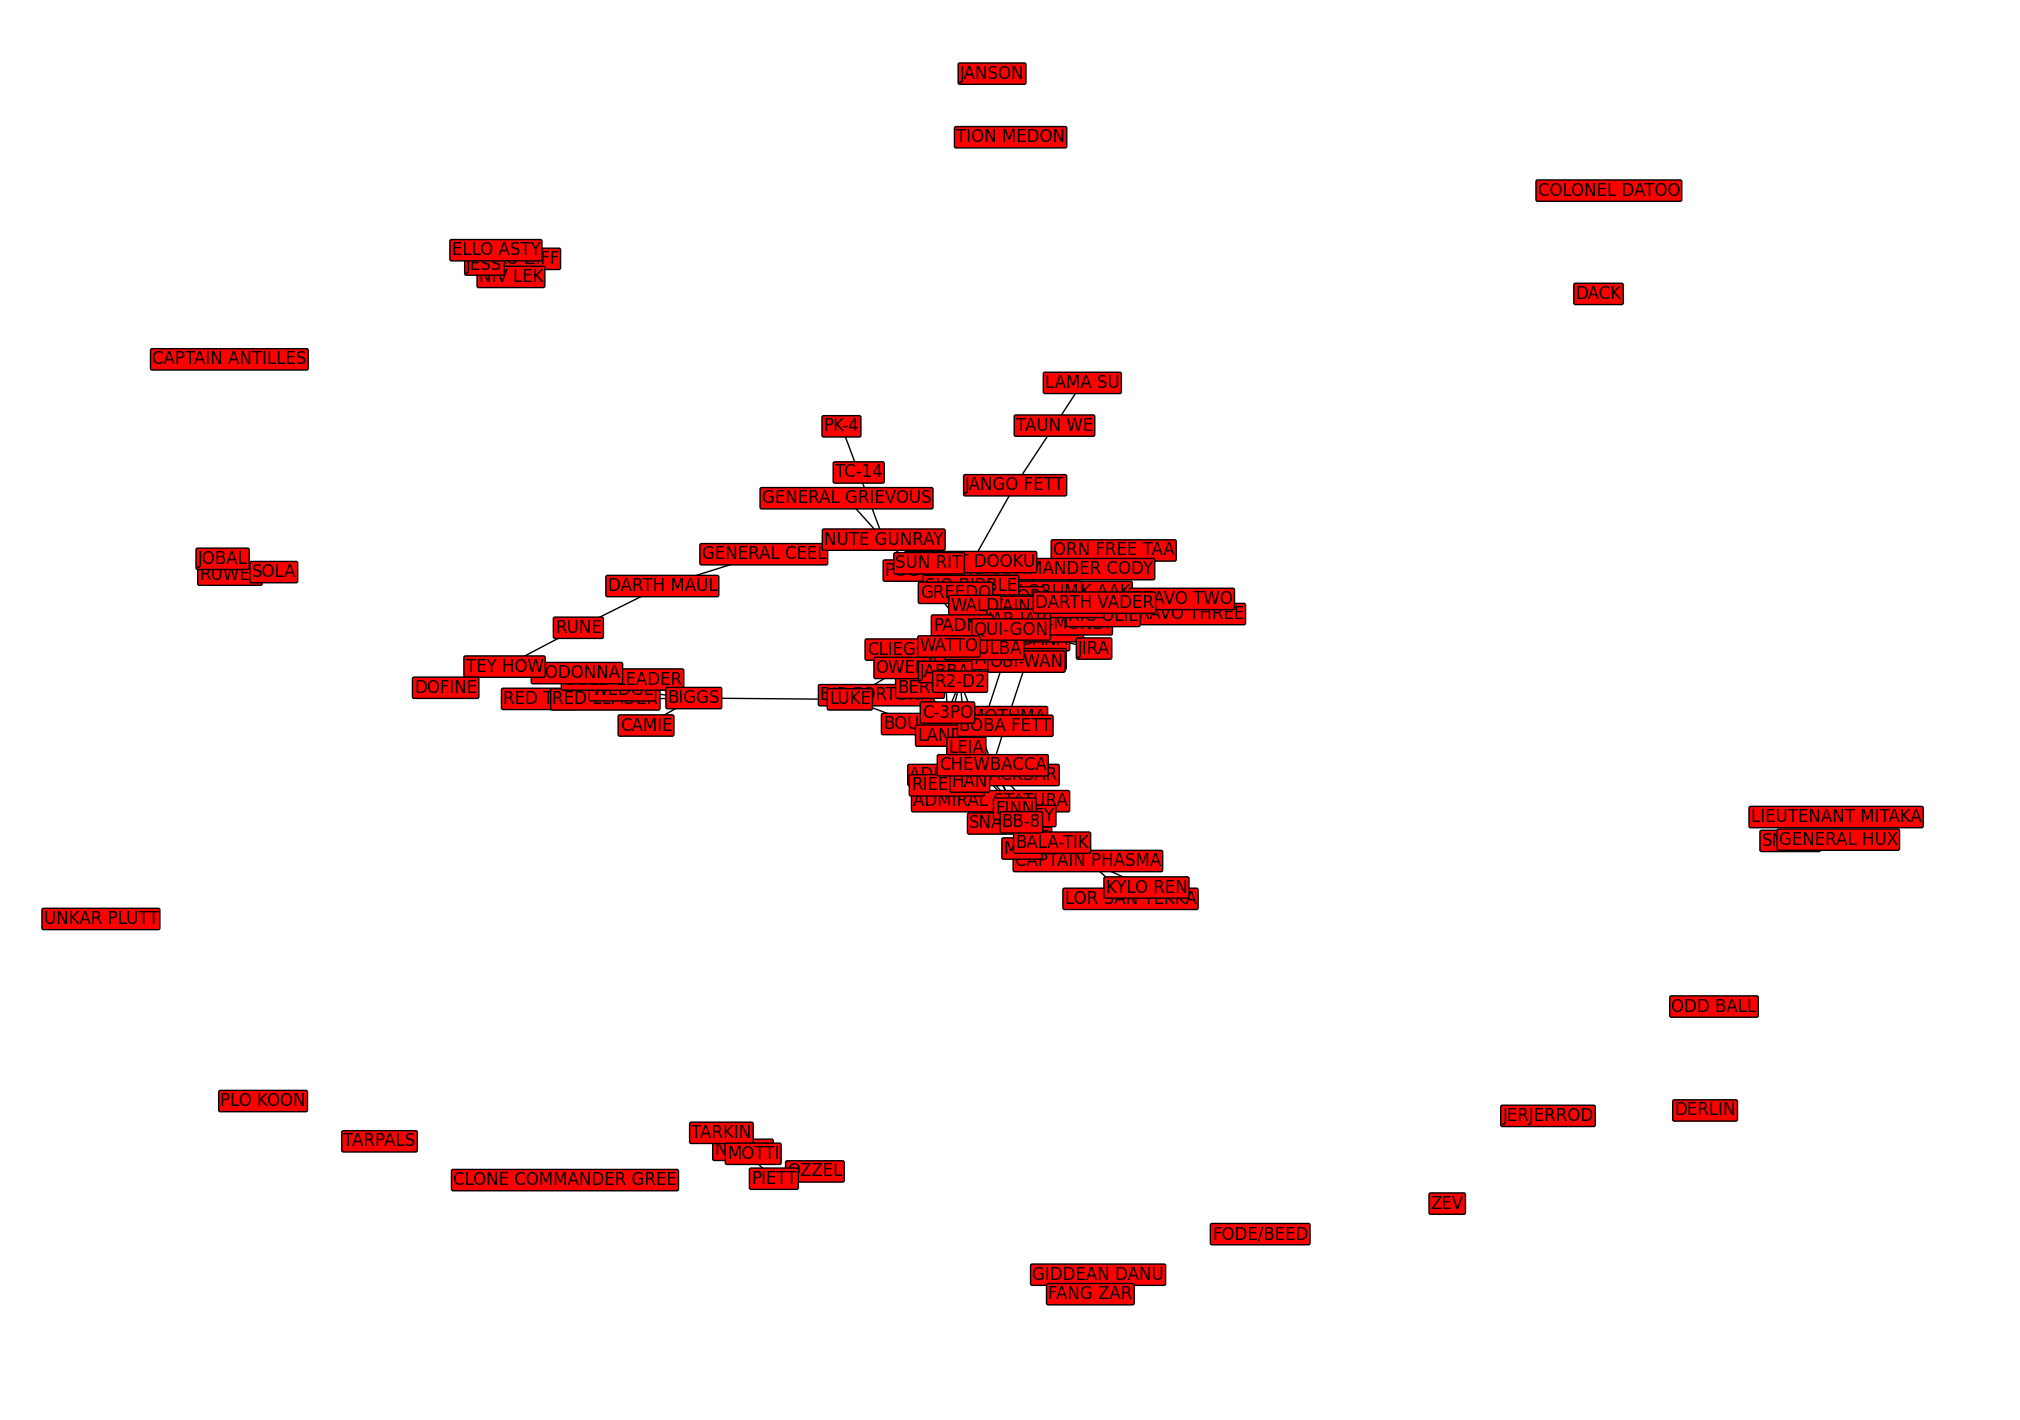

In [10]:
# LEAVE AS-IS

g50b = remove_edges_by_betweenness(g, 0.50)
plot_graph(g50b)

In the graph where 50% of the edges were removed by betweenness, there are more singletons and not only a single big connected component in comparison with the graph where 50% of the edges were removed uniformly at random, in which there are fewer singletons and a single bigger connected component. This might be because when you eliminate edges by betweenness, you eliminate more key bridges and for this reason, the network becomes more vulnerable to destruction than doing it by randomness. That's why in the betweenness one, there are more singletons and it is more sparse.

# 3. Number of connected components

In [ ]:
def assign_component_recursive(g, node2componentid, starting_node, component_id):
    node2componentid[starting_node] = component_id

    for neighbor in g.neighbors(starting_node):
        if neighbor not in node2componentid:
            assign_component_recursive(g, node2componentid, neighbor, component_id)

In [ ]:
def assign_component(g):
    node2componentid = {}
    componentid = 1
    for node in g.nodes():
        if node not in node2componentid:
            assign_component_recursive(g, node2componentid, node, componentid)
            componentid += 1
    return node2componentid

In [16]:
# LEAVE AS-IS

def count_connected_components(g):
    # Call the function to assign each node to a connected component
    node2componentid = assign_component(g)

    # Count the number of distinct values in this assignment
    return len(set(node2componentid.values()))

In [17]:
# LEAVE AS-IS

def generate_graphs_by_removing_edges(graph, method):
    ncomponents_after_reducing = {}
    for p in np.arange(0.0, 1.02, 0.02):
        print("- {:.0f}% of the nodes".format(p*100))
        reduced_graph = method(graph, p)
        ncomponents_after_reducing[p] = count_connected_components(reduced_graph)
    return ncomponents_after_reducing

print("Generating graphs by removing edges uniformly at random")
components_removing_uniformly_at_random = generate_graphs_by_removing_edges(g, remove_edges_uniformly_at_random)

print("Generating graphs by removing edges by betweenness")
components_removing_by_betweenness = generate_graphs_by_removing_edges(g, remove_edges_by_betweenness)

Generating graphs by removing edges uniformly at random
- 0% of the nodes
- 2% of the nodes
- 4% of the nodes
- 6% of the nodes
- 8% of the nodes
- 10% of the nodes
- 12% of the nodes
- 14% of the nodes
- 16% of the nodes
- 18% of the nodes
- 20% of the nodes
- 22% of the nodes
- 24% of the nodes
- 26% of the nodes
- 28% of the nodes
- 30% of the nodes
- 32% of the nodes
- 34% of the nodes
- 36% of the nodes
- 38% of the nodes
- 40% of the nodes
- 42% of the nodes
- 44% of the nodes
- 46% of the nodes
- 48% of the nodes
- 50% of the nodes
- 52% of the nodes
- 54% of the nodes
- 56% of the nodes
- 58% of the nodes
- 60% of the nodes
- 62% of the nodes
- 64% of the nodes
- 66% of the nodes
- 68% of the nodes
- 70% of the nodes
- 72% of the nodes
- 74% of the nodes
- 76% of the nodes
- 78% of the nodes
- 80% of the nodes
- 82% of the nodes
- 84% of the nodes
- 86% of the nodes
- 88% of the nodes
- 90% of the nodes
- 92% of the nodes
- 94% of the nodes
- 96% of the nodes
- 98% of the nodes

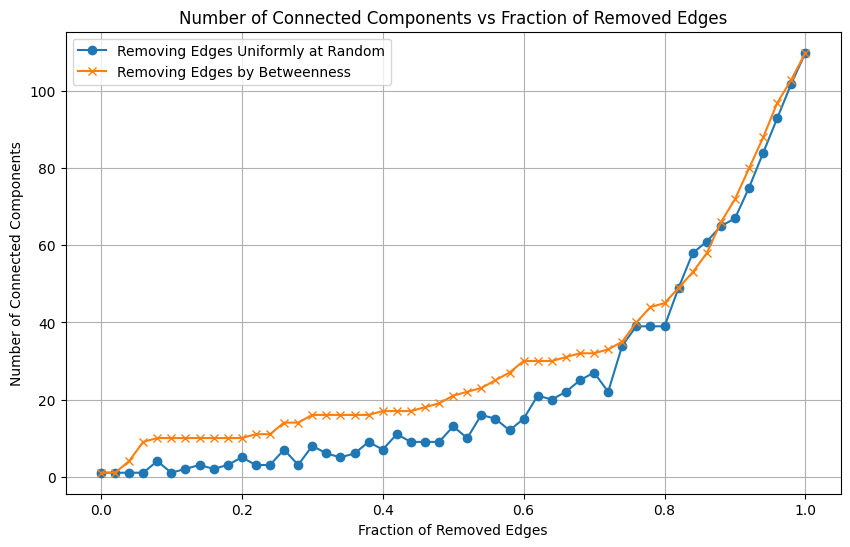

In [ ]:
plt.figure(figsize=(10, 6))

x_vals_random = sorted(components_removing_uniformly_at_random.keys())
y_vals_random = [components_removing_uniformly_at_random[x] for x in x_vals_random]
plt.plot(x_vals_random, y_vals_random, label='Removing Edges Uniformly at Random', marker='o')

x_vals_betweenness = sorted(components_removing_by_betweenness.keys())
y_vals_betweenness = [components_removing_by_betweenness[x] for x in x_vals_betweenness]
plt.plot(x_vals_betweenness, y_vals_betweenness, label='Removing Edges by Betweenness', marker='x')

plt.xlabel('Fraction of Removed Edges')
plt.ylabel('Number of Connected Components')
plt.title('Number of Connected Components vs Fraction of Removed Edges')
plt.legend()
plt.grid(True)
plt.show()

We observe a non-linear trend in both cases, where the number of connected components initially rises gradually and then quickly increases as more edges are removed. Removing edges by betweenness leads to faster fragmentation compared to random removal, highlighting the importance of high-betweenness edges in maintaining network connectivity. At 100% edge removal, the number of connected components reaches its maximum because each node becomes alone.

# 4. Largest connected component

In [ ]:
def size_largest_connected_component(g):
    node2componentid = assign_component(g)
    component_sizes = {}
    
    for component_id in node2componentid.values():
        if component_id not in component_sizes:
            component_sizes[component_id] = 0
        component_sizes[component_id] += 1

    return np.max(list(component_sizes.values()))

In [ ]:
largest_wcc_removing_uniformly_at_random = {}
largest_wcc_removing_by_betweenness = {}

for p in np.arange(0.0, 1.02, 0.02):
    print(f"Processing {p*100:.0f}% of edges removed")

    reduced_graph_random = remove_edges_uniformly_at_random(g, p)
    largest_wcc_removing_uniformly_at_random[p] = size_largest_connected_component(reduced_graph_random) / g.number_of_nodes()

    reduced_graph_betweenness = remove_edges_by_betweenness(g, p)
    largest_wcc_removing_by_betweenness[p] = size_largest_connected_component(reduced_graph_betweenness) / g.number_of_nodes()


Processing 0% of edges removed
Processing 2% of edges removed
Processing 4% of edges removed
Processing 6% of edges removed
Processing 8% of edges removed
Processing 10% of edges removed
Processing 12% of edges removed
Processing 14% of edges removed
Processing 16% of edges removed
Processing 18% of edges removed
Processing 20% of edges removed
Processing 22% of edges removed
Processing 24% of edges removed
Processing 26% of edges removed
Processing 28% of edges removed
Processing 30% of edges removed
Processing 32% of edges removed
Processing 34% of edges removed
Processing 36% of edges removed
Processing 38% of edges removed
Processing 40% of edges removed
Processing 42% of edges removed
Processing 44% of edges removed
Processing 46% of edges removed
Processing 48% of edges removed
Processing 50% of edges removed
Processing 52% of edges removed
Processing 54% of edges removed
Processing 56% of edges removed
Processing 58% of edges removed
Processing 60% of edges removed
Processing 62

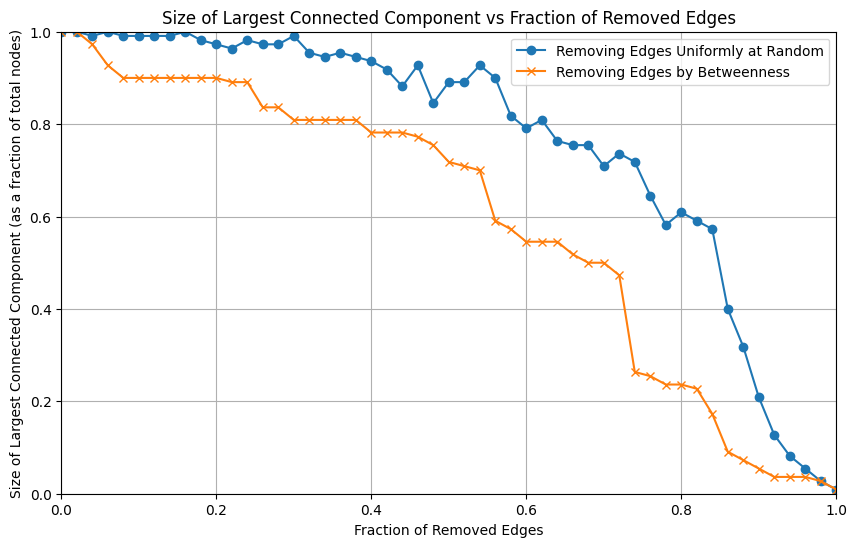

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(x_vals_random, y_vals_random, label='Removing Edges Uniformly at Random', marker='o')

plt.plot(x_vals_betweenness, y_vals_betweenness, label='Removing Edges by Betweenness', marker='x')

plt.xlabel('Fraction of Removed Edges')
plt.ylabel('Size of Largest Connected Component (as a fraction of total nodes)')
plt.title('Size of Largest Connected Component vs Fraction of Removed Edges')
plt.legend()
plt.grid(True)
plt.xlim(0.0, 1.0)
plt.ylim(0.0, 1.0)
plt.show()

We can observe that, to reduce the size of the largest connected component in the random removal, you need to remove approximately 45%. In the case of the betweenness removal, the percentage you need to remove is approximately 10%. The behavior is so different because, when removing edges randomly, it is harder to affect the size of the largest connected component because it has a lot of edges connecting all nodes. But when removing by betweenness, it is easier to affect the largest connected component because the edges in the largest connected component all have a lot of edge betweenness.

# 5. K-core decomposition

In [22]:
# LEAVE AS-IS

def get_max_degree(g):
    degree_sequence = [x[1] for x in g.degree()]
    return(max(degree_sequence))


def nodes_with_degree_less_or_equal_than(g, degree):
    nodes = []
    for node in g.nodes():
        if g.degree(node) <= degree:
            nodes.append(node)
    return nodes

In [ ]:
def kcore_decomposition(graph):
    g = graph.copy()
    
    max_degree = get_max_degree(g)
    
    node_to_level = {}
    for level in range(1, max_degree + 1):
        while True:
            nodes_in_level = nodes_with_degree_less_or_equal_than(g, level)
            if len(nodes_in_level) == 0:
                break
            
            for node in nodes_in_level:
                node_to_level[node] = level
                g.remove_node(node)
    
    return node_to_level

In [24]:
# LEAVE AS-IS

node_to_kcore = kcore_decomposition(g)

for character in ["JANSON", "RED TEN", "LUKE", "YODA"]:
    print("K-core of {:s}: {:d}".format(character, node_to_kcore[character]))

K-core of JANSON: 1
K-core of RED TEN: 2
K-core of LUKE: 7
K-core of YODA: 8


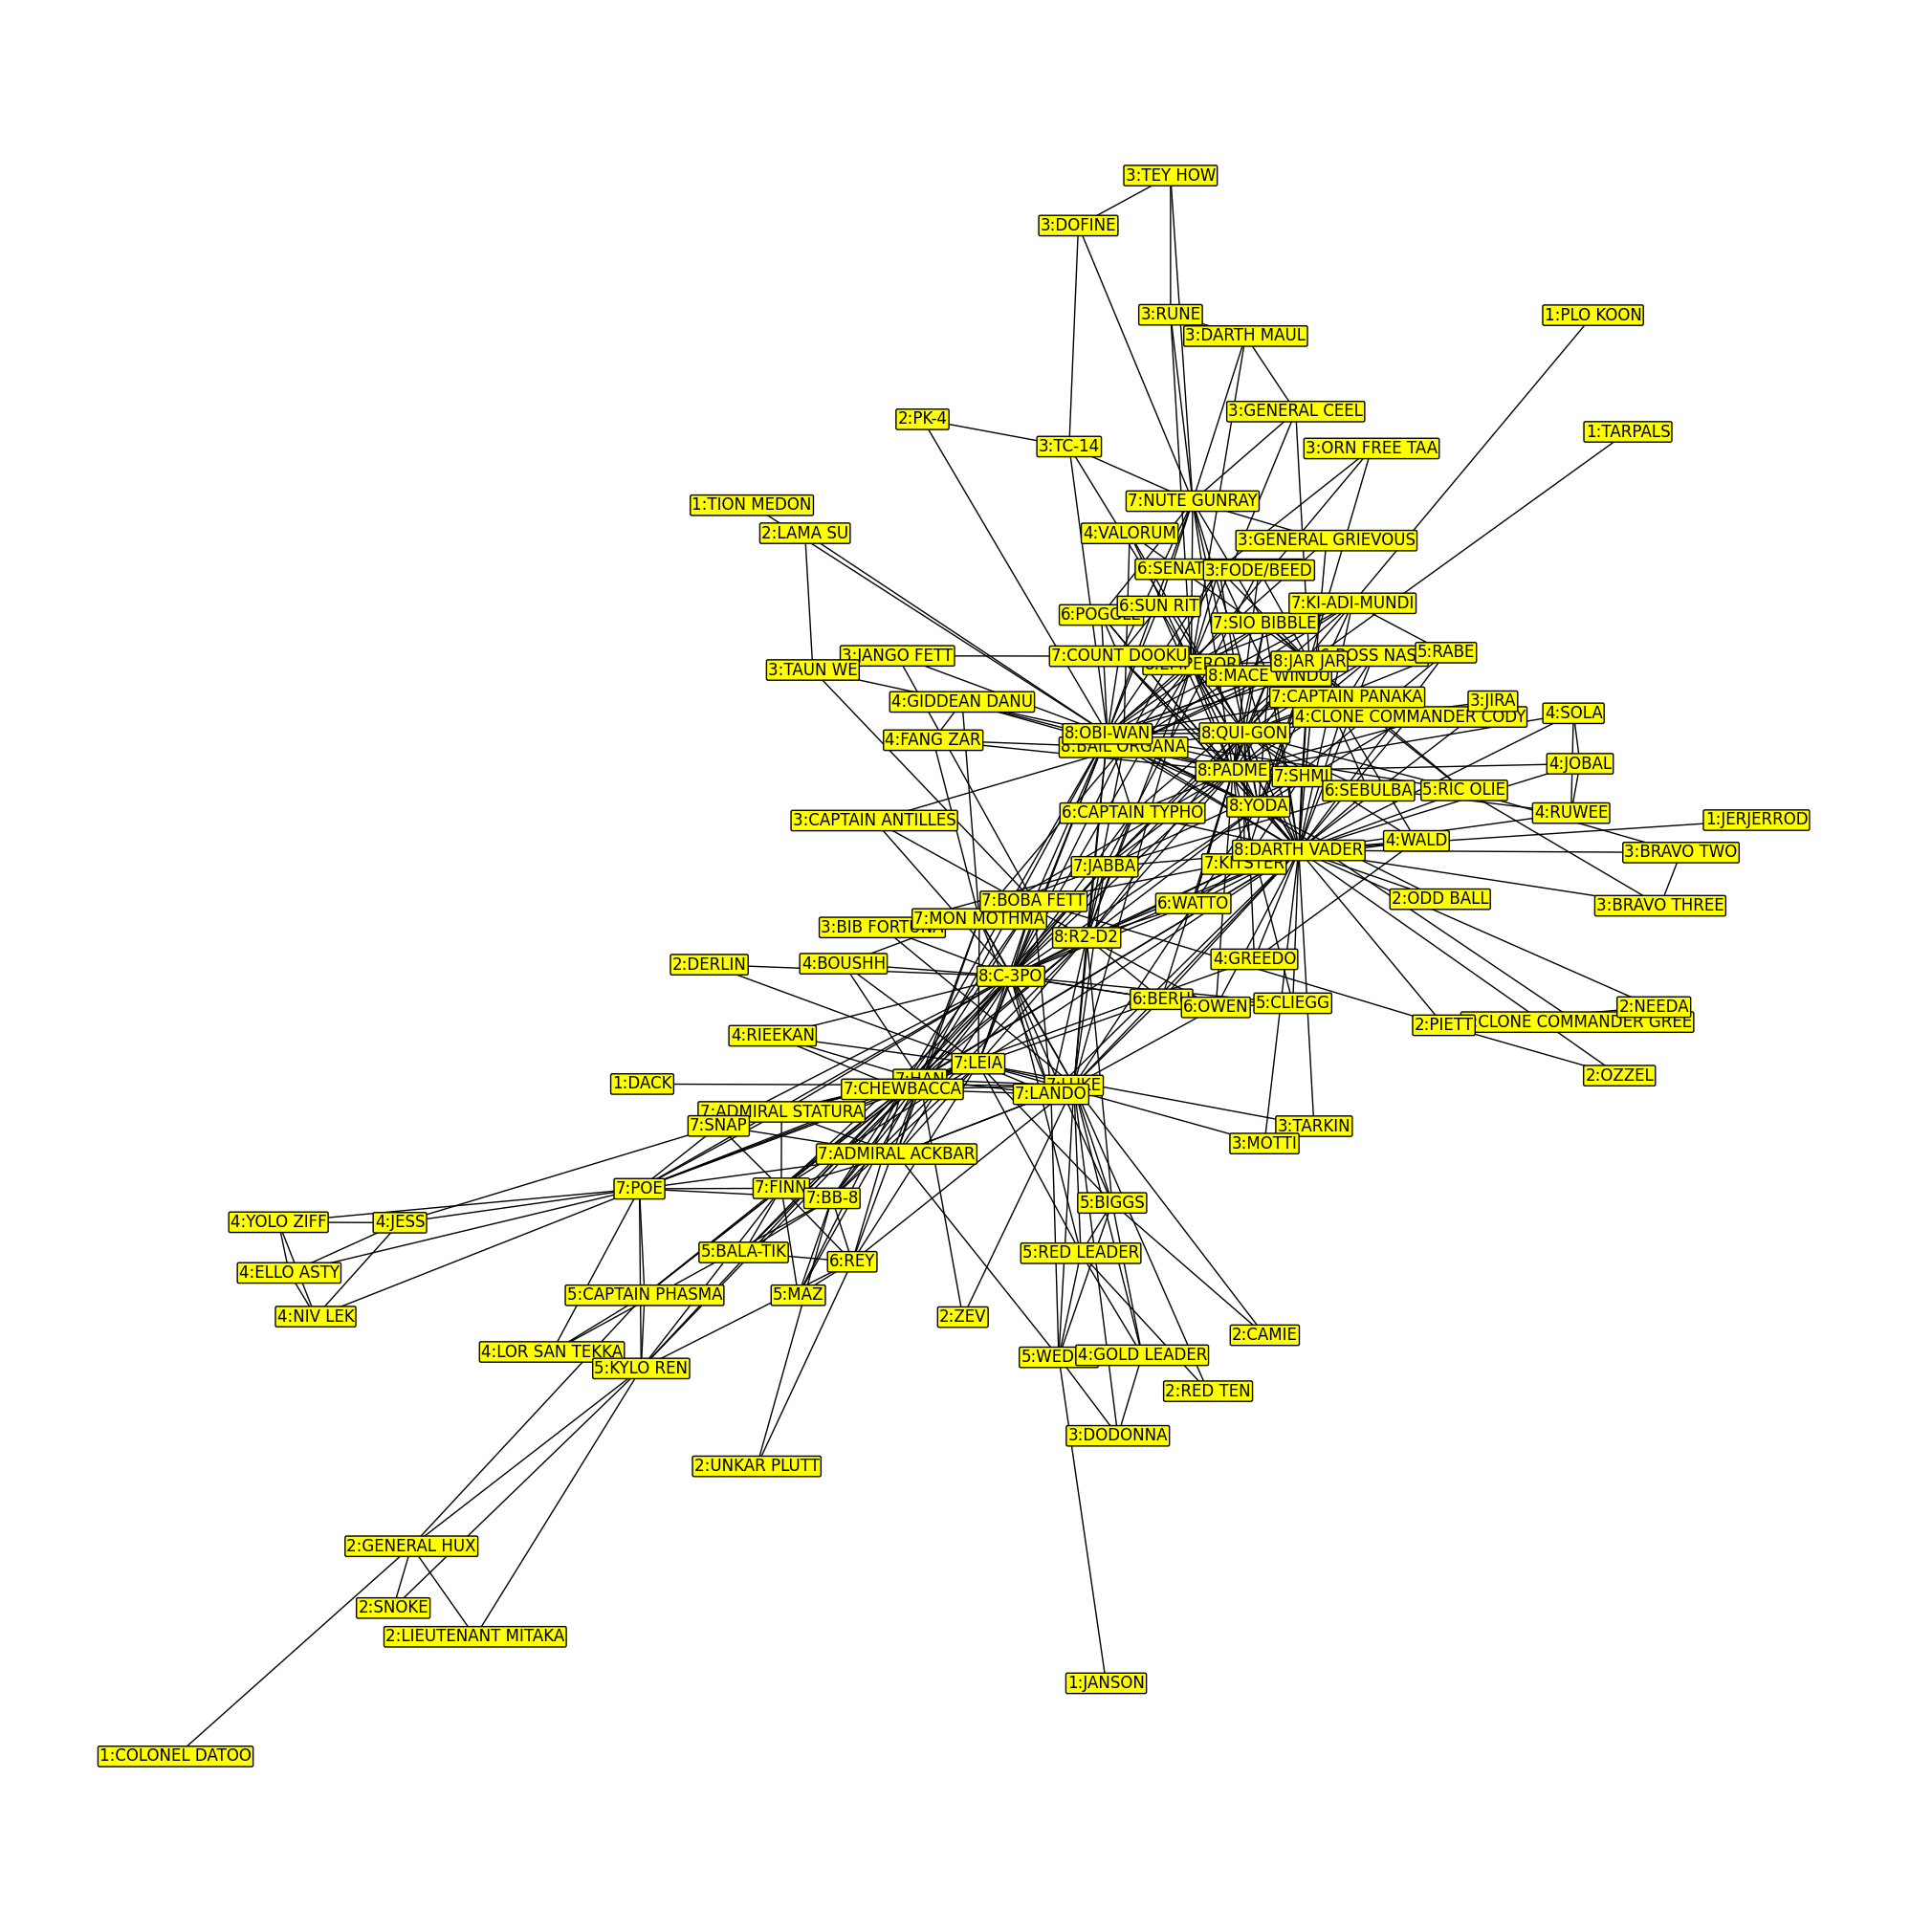

In [25]:
# LEAVE AS-IS

# Compute k-core decomposition
node_to_kcore = kcore_decomposition(g)

# Rename nodes so they include the k-core
node_to_kcore_texts = dict([(name, str(node_to_kcore[name]) + ":" + name) for name in g.nodes()])
h = nx.relabel_nodes(g, node_to_kcore_texts)

# Draw the graph
plt.figure(figsize=(20,20))
nx.draw_spring(h, with_labels=True, node_size=1, bbox=dict(facecolor="yellow", edgecolor='black', boxstyle='round,pad=0.1'))
plt.show()

We can observe how the kind of characters in the lower k-core levels have a less central role in the saga. However, the nodes with a higher k-core have a very important role in the saga and are the main characters. For example, R2-D2 or C-3PO are important characters in the saga and both have a high k-core number.

<font size="+2" color="#003300">I hereby declare that, except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>